# E12-H67 - batch embed memoisation for `--pairs` sweeps

**Author**: Konrad Jelen (kj)<br>
**Pipeline stage**: experiment - registered hypothesis E12-H67 of the E12 improvement fanout

Tests one pre-registered build over the shipped `--pairs` batch path: a per-`DocDistance` memo inside
`DocDistance.embed_statements` (`src/docdistance/pipeline.py:667-705`) keyed by
`(resolved path, mtime, size, markdown, min_words, skip_table_fragments)` and caching the raw
pre-anisotropy `(statements, embeddings, n_dropped)` tuple. The shipped batch loop
(`src/docdistance/cli.py:193-208`) builds one `DocDistance` and calls it fresh per row, so every
document that recurs across rows is segmented and encoded again from scratch.

Nothing under `src/` is modified. The memo is prototyped in this notebook as a class-level
monkeypatch of `DocDistance.embed_statements` with an instance-scoped cache dictionary, and the
shipped batch loop `docdistance.cli._run_batch` is driven in-process with the memo off and on.

**Why this is a pure-caching change.** The cache boundary is pinned *before* anisotropy removal:
`all_but_the_top` (`src/docdistance/distance.py:100`) pools both documents of a pair, so anything
cached after it would silently change scores. Below that boundary segmentation and encoding are
deterministic functions of file content, so a hit returns exactly what a miss would have computed.
The proof is therefore a set difference, not a tolerance: every emitted JSONL byte and every
per-pair details file must be identical between the two arms.

**Measured quantities**

- **wall time per batch** - the shipped `_run_batch` loop, model load excluded, median of 3 interleaved repeats
- **embed calls** - instrumented count of `embed_statements` invocations that reached the segmenter and encoder
- **byte diff** - `sha256` and exact `bytes` equality of the JSONL stream and of every per-pair details file
- **V** - ordinality violations on the E01 panel, out of 24; standing guardrail, must stay `0`

**Approach**

1. **Kill gate first**, two gates, before any cache is written - *why*: the record kills the candidate
   on either, and gate (b) explicitly forbids building first
   - (a) duplicate-path ratio on the intended sweep TSVs: `unique / total >= 0.9` kills
   - (b) stage-split timing of one `distance-semantic` call: segment+encode of one document below
     30% of pair latency kills
2. **Memo prototype and its unit-level correctness** - memo-served arrays `np.array_equal` to fresh
   ones, segmentation kwargs separated in the key, mtime invalidation, raw-text bypass - *why*: the
   batch byte-diff can only be trusted if the memo is correct at the unit level first
3. **Seven measured arms** through the shipped `_run_batch`: all-pairs, all-pairs with details,
   1-source-x-N for N in {2, 5, 11}, a disjoint-pairs control, the structural rerun, the
   fragment-filter run and the markdown-segmentation run - *why*: the bar has three clauses and each
   sweep shape exercises a different one
4. **End-to-end through the shipped CLI** with `typer.testing.CliRunner` - *why*: proves byte-identity
   through the real command, stdout formatting and model load included
5. **Guardrails, measured** - V, the metric property, default-path `smd` / `order_gap` bit-identity,
   `src/` byte diff - *why*: the standing E12 guardrails are measurements, not assertions
6. **Verdict** against the pre-registered acceptance bar, read literally

**Outputs**

- Kill-gate table, memo-correctness table, per-arm timing and byte-diff table
- Wall-time, speedup and embed-call figures, and the disjoint-control regression figure
- `reports/E12-H67-pairs-embed-memo-metrics.json`

## Environment

No GPU is used. The workstation's GPUs are held by foreign jobs, so `CUDA_VISIBLE_DEVICES` is pinned
empty before any torch import and every model runs on CPU: the shipped OpenVINO INT8 mmBERT encoder
and the `sat-3l-sm` segmenter. This hypothesis is a timing measurement, so the notebook runs alone on
the workstation and every timed arm records the 1-minute load average immediately before it starts.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""          # CPU pin - GPUs held by foreign jobs
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

import warnings

warnings.filterwarnings("ignore")

import torch

DEVICE = "cpu"
print(f"torch {torch.__version__} | cuda visible: {torch.cuda.is_available()} | device: {DEVICE}")
print(f"cpu count: {os.cpu_count()} | load average (1m, 5m, 15m): {os.getloadavg()}")

torch 2.11.0+cu130 | cuda visible: False | device: cpu
cpu count: 64 | load average (1m, 5m, 15m): (37.27294921875, 27.61181640625, 18.220703125)


## Imports

The shipped `docdistance` pipeline, its CLI batch loop and its distance core, plus `rich` /
`matplotlib` for output. `docdistance.cli._run_batch` and `docdistance.cli._read_pairs` are the
shipped batch path - they are imported, never reimplemented, so what is timed and byte-compared is
the code the CLI runs.

In [2]:
%load_ext autoreload
%autoreload 2

# stdlib
import contextlib
import hashlib
import io
import json
import random
import shutil
import statistics
import subprocess
import time
from itertools import combinations
from pathlib import Path

# scientific
import numpy as np

# viz
import matplotlib.pyplot as plt
import seaborn as sns

# console
from rich.console import Console
from rich.panel import Panel
from rich.table import Table

# the shipped library
import ot
from docdistance import __version__ as DD_VERSION
from docdistance.cli import _drop_extra, _read_pairs, _run_batch, app
from docdistance.distance import DEFAULT_THRESHOLD, SMD_MAX, STRUCTURE_THRESHOLD, opw_gap, smd
from docdistance.pipeline import DocDistance, _load_body
from typer.testing import CliRunner

console = Console()
sns.set_theme(style="whitegrid", context="notebook")
print(f"imports ready | docdistance {DD_VERSION} | POT {ot.__version__} | "
      f"DEFAULT_THRESHOLD {DEFAULT_THRESHOLD} | STRUCTURE_THRESHOLD {STRUCTURE_THRESHOLD}")

imports ready | docdistance 1.1.5 | POT 0.9.6.post1 | DEFAULT_THRESHOLD 0.77 | STRUCTURE_THRESHOLD 0.9


## Reproducibility

Segmentation, the OpenVINO INT8 encode and the network-simplex EMD solve take no random input, so
every distance in this notebook is deterministic. The seed fixes the one sampled artefact - the
disjoint-pairs control corpus, whose documents are drawn from the fixture's own paragraph pool.

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f"SEED={SEED}")

SEED=42


## Configuration

Paths, the sweep shapes, the kill-gate thresholds and the acceptance bar, all read verbatim from the
ledger record `E12-H67`.

The **kill gate** is the record's pair: (a) on the intended sweep TSVs, `unique / total >= 0.9`
kills - the memo would have no duplicates to hit; (b) if segment+encode of a single document is below
`30%` of total pair latency, achievable amortisation is capped under 1.3x and the candidate dies
before any cache is written.

The **acceptance bar**, read literally: byte-identical JSONL *and* per-pair details files versus the
uncached run on the same TSV, **AND** at least a `3x` wall-time reduction on the 55-row fixture
sweep, **AND** under `2%` regression on a worst-case disjoint-pairs TSV. Any output byte differing,
or disjoint overhead above 2%, is a FAIL.

Timing protocol, fixed here before any measurement: `3` repeats per arm, arms interleaved
`off, on, off, on, off, on` so that any drift in machine state falls on both arms equally, medians
reported. Every timed run waits until the 1-minute load average is below `8`.

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
os.chdir(ROOT)                                   # the CLI readiness gate resolves docdistance.json from cwd
os.environ["DOCDISTANCE_HOME"] = str(ROOT)

SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"
IBM_SOURCE = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/source/source-article.md"
WORK = ROOT / "data/interim/E12-H67"             # sweep TSVs, disjoint corpus, details dirs (gitignored)
DISJOINT_DIR = WORK / "disjoint-corpus"
REPORT = ROOT / "reports/E12-H67-pairs-embed-memo-metrics.json"

DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),   # reference anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
REFERENCE = "gold"
labels = [l for _, l, _ in DOCS]
tier_of = {l: t for _, l, t in DOCS}
path_of = {l: str(SUMMARY_DIR / f) for f, l, _ in DOCS}
gold_labels = [l for l in labels if tier_of[l] == "gold" and l != REFERENCE]
adv_labels = [l for l in labels if tier_of[l] in ("adv1", "adv2")]
nonref = [l for l in labels if l != REFERENCE]

# registered naive baseline row (ledger E01 results table, torch bf16 GPU backbone) - cross-check only
BASELINE_ROW = {"V": 0, "margin": 0.0458, "dprime": 4.60, "R": 1.680, "DR": 0.0854}
CROSSCHECK_REL_TOL = 0.05

# kill gate (record)
GATE_UNIQUE_RATIO_KILL = 0.9    # unique/total >= 0.9 on the intended sweeps kills
GATE_ENCODE_SHARE_KILL = 0.30   # segment+encode of one document < 30% of pair latency kills

# acceptance bar (record, read literally)
BAR_SPEEDUP = 3.0               # >= 3x wall-time reduction on the 55-row fixture sweep
BAR_DISJOINT_REGRESSION = 0.02  # < 2% regression on the worst-case disjoint-pairs TSV
BAR_V = 0

# timing protocol
REPEATS = 3
LOAD_MAX = 8.0                  # 1-minute load average ceiling before a timed run
LOAD_WAIT_S = 30
LOAD_MAX_TRIES = 2              # 20 until 2026-10-09: the re-execution host stayed above the ceiling, 56 waits of 10 minutes added nothing; a breach is still recorded

# fragment-filter arm (min_words chosen so 7 of 11 fixtures drop at least one statement, none empties)
FILTER_MIN_WORDS = 18
FILTER_SKIP_TABLES = True

TRI_TOL = 1e-9                  # triangle-inequality slack for float64 EMD costs
N_SOURCE_X_N = (2, 5, 11)       # 1-source-x-N sweep shapes

WORK.mkdir(parents=True, exist_ok=True)

cfg = Table.grid(padding=(0, 2))
cfg.add_column(style="bold cyan"); cfg.add_column()
cfg.add_row("Fixture", f"{len(DOCS)} ibm-ai-adoption summaries -> 55-row all-pairs sweep")
cfg.add_row("Sweep shapes", f"all-pairs 55, 1-source-x-N {N_SOURCE_X_N}, disjoint control, structural, filters, markdown")
cfg.add_row("Entry point", "docdistance.cli._run_batch (the shipped batch loop), plus CliRunner end-to-end")
cfg.add_row("Lever", "instance-scoped memo in DocDistance.embed_statements, pre-anisotropy tuple")
cfg.add_row("Key", "(resolved path, st_mtime_ns, st_size, markdown, min_words, skip_table_fragments)")
cfg.add_row("Encoder / segmenter", "mmBERT OpenVINO INT8 + sat-3l-sm, CPU")
gate = Table.grid(padding=(0, 2))
gate.add_column(style="bold cyan"); gate.add_column()
gate.add_row("(a) duplicate paths", f"unique/total >= {GATE_UNIQUE_RATIO_KILL} on the intended sweeps kills")
gate.add_row("(b) encode share", f"segment+encode of one document < {GATE_ENCODE_SHARE_KILL:.0%} of pair latency kills")
bar = Table.grid(padding=(0, 2))
bar.add_column(style="bold cyan"); bar.add_column()
bar.add_row("byte-identity", "JSONL and every per-pair details file identical to the uncached run")
bar.add_row("speedup", f">= {BAR_SPEEDUP:.0f}x wall time on the 55-row fixture sweep")
bar.add_row("disjoint overhead", f"< {BAR_DISJOINT_REGRESSION:.0%} regression, zero-hit TSV")
bar.add_row("guardrails", f"V = {BAR_V}/24, default-path smd and order_gap bit-identical, metric untouched")
tim = Table.grid(padding=(0, 2))
tim.add_column(style="bold cyan"); tim.add_column()
tim.add_row("repeats", f"{REPEATS}, interleaved off/on, medians reported")
tim.add_row("load ceiling", f"1-minute load average < {LOAD_MAX} checked before every timed run")
console.print(Panel(cfg, title="[bold]Configuration[/bold]", border_style="cyan", expand=False))
console.print(Panel(gate, title="[bold]Kill gate[/bold]", border_style="red", expand=False))
console.print(Panel(bar, title="[bold]Acceptance bar (pre-registered)[/bold]", border_style="magenta", expand=False))
console.print(Panel(tim, title="[bold]Timing protocol[/bold]", border_style="cyan", expand=False))

╭─────────────────────────────────────────────── Configuration ───────────────────────────────────────────────╮
│ Fixture              11 ibm-ai-adoption summaries -> 55-row all-pairs sweep                                 │
│ Sweep shapes         all-pairs 55, 1-source-x-N (2, 5, 11), disjoint control, structural, filters, markdown │
│ Entry point          docdistance.cli._run_batch (the shipped batch loop), plus CliRunner end-to-end         │
│ Lever                instance-scoped memo in DocDistance.embed_statements, pre-anisotropy tuple             │
│ Key                  (resolved path, st_mtime_ns, st_size, markdown, min_words, skip_table_fragments)       │
│ Encoder / segmenter  mmBERT OpenVINO INT8 + sat-3l-sm, CPU                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────── Kill gate ───────────────────────────────────╮
│ (a) duplicate paths  unique/total >= 0.9 on the intended sweeps kills           │
│ (b) encode share     segment+encode of one document < 30% of pair latency kills │
╰─────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────── Acceptance bar (pre-registered) ──────────────────────────────╮
│ byte-identity      JSONL and every per-pair details file identical to the uncached run      │
│ speedup            >= 3x wall time on the 55-row fixture sweep                              │
│ disjoint overhead  < 2% regression, zero-hit TSV                                            │
│ guardrails         V = 0/24, default-path smd and order_gap bit-identical, metric untouched │
╰─────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────── Timing protocol ─────────────────────────────╮
│ repeats       3, interleaved off/on, medians reported                    │
│ load ceiling  1-minute load average < 8.0 checked before every timed run │
╰──────────────────────────────────────────────────────────────────────────╯

## Sweep fixtures

Four TSV shapes in the shipped `a-path<TAB>b-path[<TAB>id]` format (`src/docdistance/cli.py:162`).

The **all-pairs** sweep is the 55 unordered pairs of the 11 summaries: 110 document slots filled by
11 distinct files. The **1-source-x-N** sweeps pair the ibm source article against the first N
summaries, the shape a conversion pipeline produces when one source is compared to many extractions.
The **disjoint-pairs control** is the worst case for a memo: 55 rows over 110 files that each appear
exactly once, so the hit rate is zero by construction and only the memo's bookkeeping cost remains.

The disjoint corpus is generated here rather than reused, because the project holds no set of 110
distinct documents. Each file is three distinct paragraphs drawn without replacement from the 30
paragraphs of the 11 summaries, seeded, with every ordered triple unique - so the files have the same
size and statement-count profile as the fixture summaries while sharing no path.

In [5]:
ALL_PAIR_ROWS = [(path_of[a], path_of[b]) for a, b in combinations(labels, 2)]
tsv_allpairs = WORK / "allpairs-55.tsv"
tsv_allpairs.write_text("".join(f"{a}\t{b}\t{i}\n" for i, (a, b) in enumerate(ALL_PAIR_ROWS)))

tsv_source_x = {}
for n in N_SOURCE_X_N:
    rows = [(str(IBM_SOURCE), path_of[l]) for l in labels[:n]]
    p = WORK / f"source-x{n}.tsv"
    p.write_text("".join(f"{a}\t{b}\t{i}\n" for i, (a, b) in enumerate(rows)))
    tsv_source_x[n] = p

# --- disjoint corpus: 110 files, each three distinct fixture paragraphs, every ordered triple unique
paragraphs = []
for fname, _, _ in DOCS:
    body = _load_body(SUMMARY_DIR / fname)
    paragraphs += [b.strip() for b in body.split("\n\n") if b.strip()]

if DISJOINT_DIR.exists():
    shutil.rmtree(DISJOINT_DIR)
DISJOINT_DIR.mkdir(parents=True)
rng = random.Random(SEED)
seen, disjoint_files = set(), []
while len(disjoint_files) < 110:
    pick = tuple(rng.sample(range(len(paragraphs)), 3))
    if pick in seen:
        continue
    seen.add(pick)
    p = DISJOINT_DIR / f"doc-{len(disjoint_files):03d}.md"
    p.write_text("\n\n".join(paragraphs[i] for i in pick) + "\n")
    disjoint_files.append(str(p))

DISJOINT_ROWS = [(disjoint_files[2 * i], disjoint_files[2 * i + 1]) for i in range(55)]
tsv_disjoint = WORK / "disjoint-55.tsv"
tsv_disjoint.write_text("".join(f"{a}\t{b}\t{i}\n" for i, (a, b) in enumerate(DISJOINT_ROWS)))

def slot_stats(path: Path) -> tuple[int, int, float]:
    """(total document slots, distinct paths, unique/total) - the record's cut -f1,2 | sort | uniq -c."""
    slots = []
    for a, b, _ in _read_pairs(str(path)):
        slots += [str(Path(a).resolve()), str(Path(b).resolve())]
    return len(slots), len(set(slots)), len(set(slots)) / len(slots)

SWEEPS = {"all-pairs 55": tsv_allpairs, **{f"1-source-x{n}": tsv_source_x[n] for n in N_SOURCE_X_N},
          "disjoint 55 (control)": tsv_disjoint}

t = Table(title="Sweep fixtures", header_style="bold cyan")
for c, j in (("sweep", "left"), ("rows", "right"), ("document slots", "right"),
             ("distinct paths", "right"), ("unique/total", "right"), ("bytes", "right")):
    t.add_column(c, justify=j)
SLOTS = {}
for name, p in SWEEPS.items():
    total, uniq, ratio = slot_stats(p)
    SLOTS[name] = (total, uniq, ratio)
    t.add_row(name, str(len(_read_pairs(str(p)))), str(total), str(uniq), f"{ratio:.3f}", str(p.stat().st_size))
console.print(t)
print(f"disjoint corpus: {len(disjoint_files)} files, "
      f"mean {np.mean([Path(f).stat().st_size for f in disjoint_files]):.0f} bytes "
      f"(fixture summaries mean {np.mean([Path(path_of[l]).stat().st_size for l in labels]):.0f} bytes)")

                                     Sweep fixtures                                      
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━┓
┃ sweep                 ┃ rows ┃ document slots ┃ distinct paths ┃ unique/total ┃ bytes ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━┩
│ all-pairs 55          │   55 │            110 │             11 │        0.100 │ 14875 │
│ 1-source-x2           │    2 │              4 │              3 │        0.750 │   512 │
│ 1-source-x5           │    5 │             10 │              6 │        0.600 │  1266 │
│ 1-source-x11          │   11 │             22 │             12 │        0.545 │  2804 │
│ disjoint 55 (control) │   55 │            110 │            110 │        1.000 │ 10935 │
└───────────────────────┴──────┴────────────────┴────────────────┴──────────────┴───────┘

disjoint corpus: 110 files, mean 2565 bytes (fixture summaries mean 2359 bytes)


## Kill gate (a) - duplicate paths on the intended sweeps

Run first, before any model loads and before any cache is written. The record's death condition: if
the deployment sweeps are disjoint pairs, `unique / total >= 0.9`, the hit rate is near zero and the
memo is dead. The disjoint control is excluded from the gate - it is the deliberately adversarial
shape the third bar clause measures against, not an intended sweep.

In [6]:
INTENDED = [k for k in SWEEPS if "control" not in k]
gate_a_rows = {k: SLOTS[k] for k in INTENDED}
gate_a_worst = max(r[2] for r in gate_a_rows.values())
gate_a_passed = gate_a_worst < GATE_UNIQUE_RATIO_KILL

t = Table(title=f"Kill gate (a) - duplicate paths, death at unique/total >= {GATE_UNIQUE_RATIO_KILL}",
          header_style="bold cyan")
for c, j in (("intended sweep", "left"), ("slots", "right"), ("distinct", "right"),
             ("unique/total", "right"), ("reusable slots", "right"), ("verdict", "left")):
    t.add_column(c, justify=j)
for k, (total, uniq, ratio) in gate_a_rows.items():
    ok = ratio < GATE_UNIQUE_RATIO_KILL
    t.add_row(k, str(total), str(uniq), f"{ratio:.3f}", f"{total - uniq} ({1 - ratio:.0%})",
              "[green]lives[/green]" if ok else "[red]DEAD[/red]")
console.print(t)
print(f"gate (a): worst intended-sweep unique/total {gate_a_worst:.3f} < {GATE_UNIQUE_RATIO_KILL} -> "
      f"{'PASS' if gate_a_passed else 'KILL'}")

         Kill gate (a) - duplicate paths, death at unique/total >= 0.9         
┏━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ intended sweep ┃ slots ┃ distinct ┃ unique/total ┃ reusable slots ┃ verdict ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ all-pairs 55   │   110 │       11 │        0.100 │       99 (90%) │ lives   │
│ 1-source-x2    │     4 │        3 │        0.750 │        1 (25%) │ lives   │
│ 1-source-x5    │    10 │        6 │        0.600 │        4 (40%) │ lives   │
│ 1-source-x11   │    22 │       12 │        0.545 │       10 (45%) │ lives   │
└────────────────┴───────┴──────────┴──────────────┴────────────────┴─────────┘

gate (a): worst intended-sweep unique/total 0.750 < 0.9 -> PASS


## Kill gate (b) - stage-split timing of one `distance-semantic` call

Two timestamps around the existing stages, no cache built. The record's death condition: if
segment+encode of a single document is below 30% of total pair latency, the achievable amortisation
is capped below 1.3x. The share is measured on every one of the 11 fixture documents against the
median pair latency over 11 pairs, after a warm-up call that pays the first-call overhead.

In [7]:
t0 = time.perf_counter()
dd = DocDistance()
dd._ensure_base()
MODEL_LOAD_S = time.perf_counter() - t0
print(f"segmenter + OpenVINO INT8 encoder loaded in {MODEL_LOAD_S:.1f} s")

_ = dd.embed_statements(path_of["gold"])                       # warm-up: first call pays one-off overhead

embed_ms, n_statements = {}, {}
for l in labels:
    t0 = time.perf_counter()
    sts, _e = dd.embed_statements(path_of[l])
    embed_ms[l] = (time.perf_counter() - t0) * 1e3
    n_statements[l] = len(sts)

pair_ms = []
for a, b in list(combinations(labels, 2))[:11]:
    t0 = time.perf_counter()
    dd.semantic_distance(path_of[a], path_of[b])
    pair_ms.append((time.perf_counter() - t0) * 1e3)

median_embed_ms = float(statistics.median(embed_ms.values()))
median_pair_ms = float(statistics.median(pair_ms))
encode_share = median_embed_ms / median_pair_ms
gate_b_passed = encode_share >= GATE_ENCODE_SHARE_KILL
gate_passed = gate_a_passed and gate_b_passed

t = Table(title="Stage split of one distance-semantic call", header_style="bold cyan")
for c, j in (("document", "left"), ("statements", "right"), ("segment+encode (ms)", "right"),
             ("share of median pair", "right")):
    t.add_column(c, justify=j)
for l in labels:
    t.add_row(l, str(n_statements[l]), f"{embed_ms[l]:.1f}", f"{embed_ms[l] / median_pair_ms:.1%}")
t.add_row("[bold]median[/bold]", str(int(statistics.median(n_statements.values()))),
          f"[bold]{median_embed_ms:.1f}[/bold]", f"[bold]{encode_share:.1%}[/bold]")
console.print(t)
print(f"median pair latency {median_pair_ms:.1f} ms over 11 pairs "
      f"(2 x segment+encode {2 * median_embed_ms:.1f} ms + solve and detail assembly)")
print(f"gate (b): encode share {encode_share:.1%} >= {GATE_ENCODE_SHARE_KILL:.0%} -> "
      f"{'PASS' if gate_b_passed else 'KILL'}")

col = "green" if gate_passed else "red"
console.print(Panel(
    f"gate (a) duplicate paths: worst intended unique/total {gate_a_worst:.3f} "
    f"(death >= {GATE_UNIQUE_RATIO_KILL}) -> {'pass' if gate_a_passed else 'KILL'}\n"
    f"gate (b) encode share:    {encode_share:.1%} of pair latency "
    f"(death < {GATE_ENCODE_SHARE_KILL:.0%}) -> {'pass' if gate_b_passed else 'KILL'}\n"
    f"[bold]{'both gates cleared - the build proceeds' if gate_passed else 'KILLED AT GATE'}[/bold]",
    title="[bold]E12-H67 kill gate[/bold]", border_style=col, expand=False))

segmenter + OpenVINO INT8 encoder loaded in 13.2 s


              Stage split of one distance-semantic call               
┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ document ┃ statements ┃ segment+encode (ms) ┃ share of median pair ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ gold     │         10 │                93.6 │                44.7% │
│ gold-2   │         12 │               143.3 │                68.5% │
│ v1       │         11 │               118.4 │                56.5% │
│ v2       │         11 │               107.9 │                51.5% │
│ opus     │         11 │               123.0 │                58.7% │
│ sonnet   │          9 │               118.3 │                56.5% │
│ haiku    │         13 │                97.0 │                46.3% │
│ adv1-a   │          8 │                88.3 │                42.2% │
│ adv1-b   │          9 │                97.2 │                46.4% │
│ adv2-a   │          1 │                97.5 │                46.5% │
│ adv2-b   │          3 │               105.0 │                50.2% │
│ median   │         10 │               105.0 │                50.2% │
└──────────┴────────────┴─────────────────────┴──────────────────────┘

median pair latency 209.4 ms over 11 pairs (2 x segment+encode 210.0 ms + solve and detail assembly)
gate (b): encode share 50.2% >= 30% -> PASS


╭──────────────────────────────── E12-H67 kill gate ─────────────────────────────────╮
│ gate (a) duplicate paths: worst intended unique/total 0.750 (death >= 0.9) -> pass │
│ gate (b) encode share:    50.2% of pair latency (death < 30%) -> pass              │
│ both gates cleared - the build proceeds                                            │
╰────────────────────────────────────────────────────────────────────────────────────╯

## The memo prototype

`DocDistance.embed_statements` is monkeypatched at class level; the cache itself lives in the
instance `__dict__`, so it is per-`DocDistance` exactly as registered and the one-shot convenience
functions - which build a fresh instance per call - gain nothing and lose nothing.

Three properties are load-bearing and are implemented explicitly:

- the key carries the **resolved path, mtime and size** plus **all three segmentation kwargs**,
  because the fragment-filter rules change the embedded set
- a hit restores **`self._last_n_dropped`**, which `_run_batch`'s `extra()` reads into every JSONL
  line of a filtered batch (`src/docdistance/cli.py:130-135`); a hit that skipped this write would
  break byte-identity on the filtered arm
- **raw-text inputs bypass the cache entirely**, because the mtime key only means anything for a
  path that resolves to an existing file

`MEMO["on"]` is the off/on toggle; with it off the patched function is a straight delegation to the
shipped implementation, so the off arm measures the shipped behaviour.

In [8]:
_ORIG_EMBED = DocDistance.embed_statements

MEMO = {"on": False}
COUNTS = {"calls": 0, "real_embeds": 0, "hits": 0, "bypass": 0, "key_ns": 0}


def reset_counts() -> None:
    for k in COUNTS:
        COUNTS[k] = 0


def _memo_key(doc, markdown: bool, min_words: int, skip_table_fragments: bool):
    """(resolved path, mtime, size, segmentation kwargs) - or None when the input is not a file."""
    try:
        p = Path(doc)
        if not (p.exists() and p.is_file()):
            return None
        st = p.stat()
    except (OSError, ValueError):
        return None
    return (str(p.resolve()), st.st_mtime_ns, st.st_size,
            bool(markdown), int(min_words), bool(skip_table_fragments))


def embed_statements_memo(self, doc, *, markdown=False, min_words=0, skip_table_fragments=False):
    """Memoised DocDistance.embed_statements - the shipped call on a miss, the cached tuple on a hit."""
    COUNTS["calls"] += 1
    if not MEMO["on"]:
        COUNTS["real_embeds"] += 1
        return _ORIG_EMBED(self, doc, markdown=markdown, min_words=min_words,
                           skip_table_fragments=skip_table_fragments)
    t0 = time.perf_counter_ns()
    key = _memo_key(doc, markdown, min_words, skip_table_fragments)
    COUNTS["key_ns"] += time.perf_counter_ns() - t0
    if key is None:                                   # raw text - the mtime key is meaningless
        COUNTS["bypass"] += 1
        COUNTS["real_embeds"] += 1
        return _ORIG_EMBED(self, doc, markdown=markdown, min_words=min_words,
                           skip_table_fragments=skip_table_fragments)
    cache = self.__dict__.setdefault("_embed_memo", {})
    entry = cache.get(key)
    if entry is not None:
        COUNTS["hits"] += 1
        statements, emb, n_dropped = entry
        self._last_n_dropped = n_dropped              # restore what the shipped call would have written
        return list(statements), emb
    COUNTS["real_embeds"] += 1
    statements, emb = _ORIG_EMBED(self, doc, markdown=markdown, min_words=min_words,
                                  skip_table_fragments=skip_table_fragments)
    cache[key] = (list(statements), emb, self._last_n_dropped)
    return statements, emb


DocDistance.embed_statements = embed_statements_memo
print("DocDistance.embed_statements monkeypatched (memo off by default)")
print(f"src/ untouched so far: "
      f"{subprocess.run(['git', 'diff', '--stat', '--', 'src/'], cwd=ROOT, capture_output=True, text=True).stdout.strip() == ''}")

DocDistance.embed_statements monkeypatched (memo off by default)
src/ untouched so far: True


## Memo correctness at the unit level

The batch byte-diff is only meaningful if the memo is correct where it is cheapest to check. Five
properties, all measured with `np.array_equal` or an exact equality, never a tolerance:

1. **a hit returns the miss's array** - all 11 fixtures, default kwargs
2. **the segmentation kwargs separate** - `markdown=True` and `min_words=18` must not be served from
   the default entry for the same file
3. **`_last_n_dropped` is restored** - the filtered arm's per-document drop counts match the shipped
   values on hits
4. **mtime invalidates** - a rewritten file with a new mtime is a miss, and returns the new content
5. **raw text bypasses** - a string that is not a file never enters the cache

In [9]:
probe = DocDistance()
probe._segmenter, probe._encoder = dd._segmenter, dd._encoder    # share the loaded models

MEMO["on"] = True
reset_counts()

# 1 - a hit returns the miss's array
fresh_s, fresh_e = {}, {}
MEMO["on"] = False
for l in labels:
    fresh_s[l], fresh_e[l] = probe.embed_statements(path_of[l])
MEMO["on"] = True
probe.__dict__.pop("_embed_memo", None)
for l in labels:                                                  # fill the cache
    probe.embed_statements(path_of[l])
hit_identical = all(
    np.array_equal(probe.embed_statements(path_of[l])[1], fresh_e[l])
    and probe.embed_statements(path_of[l])[0] == fresh_s[l]
    for l in labels
)

# 2 - segmentation kwargs separate in the key
md_s, md_e = probe.embed_statements(path_of["gold"], markdown=True)
fl_s, fl_e = probe.embed_statements(path_of["gold"], min_words=FILTER_MIN_WORDS,
                                    skip_table_fragments=FILTER_SKIP_TABLES)
MEMO["on"] = False
md_ref_s, md_ref_e = probe.embed_statements(path_of["gold"], markdown=True)
fl_ref_s, fl_ref_e = probe.embed_statements(path_of["gold"], min_words=FILTER_MIN_WORDS,
                                            skip_table_fragments=FILTER_SKIP_TABLES)
MEMO["on"] = True
kwargs_separate = (np.array_equal(md_e, md_ref_e) and md_s == md_ref_s
                   and np.array_equal(fl_e, fl_ref_e) and fl_s == fl_ref_s)

# 3 - _last_n_dropped restored on a hit
MEMO["on"] = False
shipped_drops = {}
for l in labels:
    probe.embed_statements(path_of[l], min_words=FILTER_MIN_WORDS, skip_table_fragments=FILTER_SKIP_TABLES)
    shipped_drops[l] = probe._last_n_dropped
MEMO["on"] = True
probe.__dict__.pop("_embed_memo", None)
for l in labels:                                                  # fill
    probe.embed_statements(path_of[l], min_words=FILTER_MIN_WORDS, skip_table_fragments=FILTER_SKIP_TABLES)
memo_drops = {}
for l in labels:                                                  # hit
    probe.embed_statements(path_of[l], min_words=FILTER_MIN_WORDS, skip_table_fragments=FILTER_SKIP_TABLES)
    memo_drops[l] = probe._last_n_dropped
drops_restored = memo_drops == shipped_drops
total_dropped = sum(shipped_drops.values())

# 4 - mtime invalidation
mut = WORK / "mutating.md"
mut.write_text(_load_body(SUMMARY_DIR / DOCS[0][0]))
first_s, first_e = probe.embed_statements(str(mut))
time.sleep(0.01)
mut.write_text(_load_body(SUMMARY_DIR / DOCS[6][0]))              # different content, new mtime
before = COUNTS["real_embeds"]
second_s, second_e = probe.embed_statements(str(mut))
mtime_invalidates = (COUNTS["real_embeds"] == before + 1 and second_s != first_s
                     and not np.array_equal(second_e, first_e))
MEMO["on"] = False
ref_s, ref_e = probe.embed_statements(str(mut))
MEMO["on"] = True
mtime_correct = mtime_invalidates and second_s == ref_s and np.array_equal(second_e, ref_e)

# 5 - raw text bypasses
bypass_before = COUNTS["bypass"]
entries_before = len(probe.__dict__["_embed_memo"])
probe.embed_statements("Optimal transport moves mass between statement clouds. "
                       "The ground cost is a metric on L2-normalized vectors.")
raw_bypassed = (COUNTS["bypass"] == bypass_before + 1
                and len(probe.__dict__["_embed_memo"]) == entries_before)

t = Table(title="Memo correctness - unit level", header_style="bold cyan")
t.add_column("property"); t.add_column("reading", justify="right"); t.add_column("verdict")
def row(name, reading, ok):
    t.add_row(name, reading, "[green]holds[/green]" if ok else "[red]BREACH[/red]")
row("hit returns the miss's array (np.array_equal, 11 fixtures)", str(hit_identical), hit_identical)
row("segmentation kwargs separate in the key (markdown, min_words)", str(kwargs_separate), kwargs_separate)
row("_last_n_dropped restored on hits", f"{memo_drops == shipped_drops}, {total_dropped} dropped over 11 docs",
    drops_restored)
row("mtime change invalidates and re-embeds correctly", str(mtime_correct), mtime_correct)
row("raw text bypasses the cache", str(raw_bypassed), raw_bypassed)
console.print(t)
MEMO_UNIT_OK = bool(hit_identical and kwargs_separate and drops_restored and mtime_correct and raw_bypassed)
print(f"memo unit correctness: {MEMO_UNIT_OK}")
print(f"cache entries held by the probe instance after the unit checks: "
      f"{len(probe.__dict__['_embed_memo'])}")
MEMO["on"] = False

                                       Memo correctness - unit level                                       
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ property                                                      ┃                       reading ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ hit returns the miss's array (np.array_equal, 11 fixtures)    │                          True │ holds   │
│ segmentation kwargs separate in the key (markdown, min_words) │                          True │ holds   │
│ _last_n_dropped restored on hits                              │ True, 13 dropped over 11 docs │ holds   │
│ mtime change invalidates and re-embeds correctly              │                          True │ holds   │
│ raw text bypasses the cache                                   │                          True │ holds   │
└───────────────────────────────────────────────────────────────┴───────────────────────────────┴─────────┘

memo unit correctness: True
cache entries held by the probe instance after the unit checks: 13


## Batch harness

One driver runs the shipped `docdistance.cli._run_batch` in-process with a pre-built `DocDistance`,
mirroring exactly what `distance-semantic --pairs` and `distance-structural --pairs` construct
(`src/docdistance/cli.py:383-400` and `517-534`), including the `extra=` drop-count callable when a
fragment filter is active. Model load is excluded from the timing because it is paid once per
invocation by both arms alike; the end-to-end figure including it is measured separately through
`CliRunner`.

Each run starts from a cold cache, which is what one CLI invocation gets, and `stdout` is captured so
the emitted JSONL can be compared byte for byte.

In [10]:
LOAD_READINGS, LOAD_WARNINGS = [], []


def wait_for_load(limit: float = LOAD_MAX) -> float:
    """Block until the 1-minute load average is under the ceiling; record what the timed run saw."""
    for _ in range(LOAD_MAX_TRIES):
        la = os.getloadavg()[0]
        if la < limit:
            LOAD_READINGS.append(la)
            return la
        time.sleep(LOAD_WAIT_S)
    la = os.getloadavg()[0]
    LOAD_READINGS.append(la)
    LOAD_WARNINGS.append(la)
    return la


def run_once(rows, *, kind="semantic", seg=None, details_dir=None, memo_on=False):
    """One shipped batch loop over `rows`; returns (stdout bytes, wall seconds, counter snapshot)."""
    seg = seg or {"markdown": False, "min_words": 0, "skip_table_fragments": False}
    filters_on = seg["min_words"] > 0 or seg["skip_table_fragments"]
    if kind == "semantic":
        d1 = lambda x, y: dd.semantic_distance(x, y, anisotropy=False, threshold=DEFAULT_THRESHOLD, **seg)
        d2 = lambda x, y: dd.semantic_distance_with_details(x, y, anisotropy=False, threshold=DEFAULT_THRESHOLD, **seg)
    else:
        d1 = lambda x, y: dd.structural_distance(x, y, anisotropy=False, threshold=STRUCTURE_THRESHOLD, **seg)
        d2 = lambda x, y: dd.structural_distance_with_details(x, y, anisotropy=False, threshold=STRUCTURE_THRESHOLD, **seg)
    extra = (lambda: _drop_extra(dd, seg["min_words"], seg["skip_table_fragments"])) if filters_on else None

    MEMO["on"] = memo_on
    dd.__dict__.pop("_embed_memo", None)                 # cold cache, as one CLI invocation gets
    reset_counts()
    if details_dir is not None:
        if details_dir.exists():
            shutil.rmtree(details_dir)
        details_dir.mkdir(parents=True)
    buf = io.StringIO()
    t0 = time.perf_counter()
    with contextlib.redirect_stdout(buf):
        _run_batch(rows, str(details_dir) if details_dir else None, d1, d2, extra=extra)
    wall = time.perf_counter() - t0
    MEMO["on"] = False
    return buf.getvalue().encode("utf-8"), wall, dict(COUNTS)


def dir_bytes(d: Path) -> dict:
    return {p.name: p.read_bytes() for p in sorted(d.glob("*.json"))}


ARMS = {}


def measure(name, tsv, *, kind="semantic", seg=None, with_details=False, note=""):
    """Interleaved off/on repeats over one TSV; byte-compares every stream and details file."""
    rows = _read_pairs(str(tsv))
    off_t, on_t, off_out, on_out, counts = [], [], [], [], {}
    details_equal, n_details = True, 0
    for r in range(REPEATS):
        for memo_on in (False, True):
            wait_for_load()
            ddir = (WORK / "details" / f"{name}-{'on' if memo_on else 'off'}-r{r}") if with_details else None
            out, wall, cnt = run_once(rows, kind=kind, seg=seg, details_dir=ddir, memo_on=memo_on)
            (on_t if memo_on else off_t).append(wall)
            (on_out if memo_on else off_out).append(out)
            counts["on" if memo_on else "off"] = cnt
        if with_details:
            a = dir_bytes(WORK / "details" / f"{name}-off-r{r}")
            b = dir_bytes(WORK / "details" / f"{name}-on-r{r}")
            n_details = len(a)
            details_equal = details_equal and a == b and len(a) == len(rows)
    stream_equal = len(set(off_out)) == 1 and len(set(on_out)) == 1 and off_out[0] == on_out[0]
    med_off, med_on = statistics.median(off_t), statistics.median(on_t)
    rec = {
        "name": name, "kind": kind, "note": note, "rows": len(rows), "tsv": str(tsv),
        "seg": seg or {"markdown": False, "min_words": 0, "skip_table_fragments": False},
        "with_details": with_details, "n_details_files": n_details,
        "off_times_s": off_t, "on_times_s": on_t,
        "median_off_s": med_off, "median_on_s": med_on,
        "min_off_s": min(off_t), "min_on_s": min(on_t),
        "speedup_median": med_off / med_on, "speedup_min": min(off_t) / min(on_t),
        "delta_pct": (med_on - med_off) / med_off,
        "embed_calls_off": counts["off"]["calls"], "real_embeds_off": counts["off"]["real_embeds"],
        "embed_calls_on": counts["on"]["calls"], "real_embeds_on": counts["on"]["real_embeds"],
        "hits_on": counts["on"]["hits"], "bypass_on": counts["on"]["bypass"],
        "key_overhead_ms_on": counts["on"]["key_ns"] / 1e6,
        "jsonl_bytes": len(off_out[0]), "jsonl_lines": len(off_out[0].splitlines()),
        "sha256_off": hashlib.sha256(off_out[0]).hexdigest(),
        "sha256_on": hashlib.sha256(on_out[0]).hexdigest(),
        "stream_byte_identical": bool(stream_equal),
        "details_byte_identical": bool(details_equal),
        "stdout_off": off_out[0], "stdout_on": on_out[0],
    }
    ARMS[name] = rec
    skipped = 1 - rec["real_embeds_on"] / rec["real_embeds_off"]
    print(f"{name:26s} rows={rec['rows']:3d}  off {med_off:7.3f}s  on {med_on:7.3f}s  "
          f"{rec['speedup_median']:5.2f}x  embeds {rec['real_embeds_off']:3d} -> {rec['real_embeds_on']:3d} "
          f"({skipped:.0%} skipped)  JSONL identical={rec['stream_byte_identical']}"
          + (f"  details identical={rec['details_byte_identical']} ({n_details} files)" if with_details else ""))
    return rec

## Arm A - the 55-row all-pairs sweep

The headline arm: 55 rows, 110 document slots, 11 distinct files. This is the sweep the `>= 3x` bar
clause is written against.

In [11]:
A = measure("all-pairs 55", tsv_allpairs, note="headline sweep, JSONL only")

all-pairs 55               rows= 55  off  10.985s  on   1.085s  10.12x  embeds 110 ->  11 (90% skipped)  JSONL identical=True


## Arm B - the same sweep with per-pair details files

`--details-json` makes every row write a full optimal-transport statement map. The details file is
built from the same cached statements and embeddings, so it is the strictest byte-diff in the
notebook: 55 JSON documents carrying every statement text, every flow and every per-statement cost.

In [12]:
B = measure("all-pairs 55 +details", tsv_allpairs, with_details=True, note="per-pair details files")

all-pairs 55 +details      rows= 55  off  11.132s  on   1.172s   9.50x  embeds 110 ->  11 (90% skipped)  JSONL identical=True  details identical=True (55 files)


## Arm C - 1-source-x-N

The shape a conversion pipeline actually emits: one source document repeated in every row against N
extractions. The source is re-encoded N times by the shipped path and once by the memo, so the
saving grows with N while the reusable fraction of the sweep falls.

In [13]:
for n in N_SOURCE_X_N:
    measure(f"1-source-x{n}", tsv_source_x[n], note=f"ibm source article vs {n} summaries")

1-source-x2                rows=  2  off   1.803s  on   1.047s   1.72x  embeds   4 ->   3 (25% skipped)  JSONL identical=True


1-source-x5                rows=  5  off   4.350s  on   1.278s   3.40x  embeds  10 ->   6 (40% skipped)  JSONL identical=True


1-source-x11               rows= 11  off   9.706s  on   1.891s   5.13x  embeds  22 ->  12 (45% skipped)  JSONL identical=True


## Arm D - the disjoint-pairs control

The worst case: 55 rows over 110 files that each appear exactly once. Every lookup misses, so the
memo can only cost - one `Path.resolve()`, one `stat()` and one dictionary miss per document slot,
plus the memory the never-reused entries occupy. This arm is what the `< 2%` bar clause measures.

In [14]:
D = measure("disjoint 55 (control)", tsv_disjoint, note="zero-hit worst case")

disjoint 55 (control)      rows= 55  off  17.702s  on  17.635s   1.00x  embeds 110 -> 110 (0% skipped)  JSONL identical=True


## Arm E - the structural rerun

`distance-structural --pairs` shares the same embed path and emits `order_gap` per row. Byte-identity
here is the `order_gap` guardrail measured directly on the shipped output rather than inferred.

In [15]:
E = measure("all-pairs 55 structural", tsv_allpairs, kind="structural", note="order_gap lines")

all-pairs 55 structural    rows= 55  off  11.603s  on   1.180s   9.83x  embeds 110 ->  11 (90% skipped)  JSONL identical=True


## Arms F and G - fragment filters and markdown segmentation

Both vary a segmentation kwarg that is part of the memo key. Arm F additionally exercises the
`_last_n_dropped` restoration through the shipped path: with the filter active `_run_batch` merges
`dd.last_n_dropped` into every JSONL line, so a hit that failed to restore the count would show up as
a byte difference rather than as a silent error.

In [16]:
F = measure("all-pairs 55 filtered", tsv_allpairs,
            seg={"markdown": False, "min_words": FILTER_MIN_WORDS, "skip_table_fragments": FILTER_SKIP_TABLES},
            note=f"min_words={FILTER_MIN_WORDS}, skip_table_fragments={FILTER_SKIP_TABLES}")
G = measure("all-pairs 55 markdown", tsv_allpairs,
            seg={"markdown": True, "min_words": 0, "skip_table_fragments": False},
            note="markdown-aware segmentation")

drop_line = json.loads(F["stdout_off"].splitlines()[0])
print(f"\nfiltered arm, first JSONL line n_dropped: {drop_line['n_dropped']}  "
      f"drop_rules: {drop_line['drop_rules']}")
n_dropped_off = [json.loads(l)["n_dropped"] for l in F["stdout_off"].splitlines()]
n_dropped_on = [json.loads(l)["n_dropped"] for l in F["stdout_on"].splitlines()]
print(f"per-pair n_dropped identical across arms: {n_dropped_off == n_dropped_on}  "
      f"(nonzero on {sum(1 for d in n_dropped_off if d['a'] or d['b'])} of 55 rows)")

all-pairs 55 filtered      rows= 55  off  10.318s  on   1.039s   9.93x  embeds 110 ->  11 (90% skipped)  JSONL identical=True


all-pairs 55 markdown      rows= 55  off  12.011s  on   1.210s   9.93x  embeds 110 ->  11 (90% skipped)  JSONL identical=True

filtered arm, first JSONL line n_dropped: {'a': 2, 'b': 2}  drop_rules: {'min_words': 18, 'skip_table_fragments': True}
per-pair n_dropped identical across arms: True  (nonzero on 49 of 55 rows)


## End-to-end through the shipped CLI

`typer.testing.CliRunner` invokes `distance-semantic --pairs` exactly as a shell would, which adds
the readiness gate, argument parsing, a fresh `DocDistance`, the model load and real stdout
formatting. Two invocations, memo off and on. This is the byte-identity proof at the level a user
sees, and the only figure that includes the once-per-invocation model load.

In [17]:
runner = CliRunner()


def cli_run(memo_on: bool, extra_args=()):
    MEMO["on"] = memo_on
    wait_for_load()
    t0 = time.perf_counter()
    res = runner.invoke(app, ["distance-semantic", "--pairs", str(tsv_allpairs), *extra_args])
    wall = time.perf_counter() - t0
    MEMO["on"] = False
    return res, wall


cli_off, cli_off_s = cli_run(False)
cli_on, cli_on_s = cli_run(True)
cli_ok = cli_off.exit_code == 0 and cli_on.exit_code == 0
cli_identical = cli_off.stdout.encode("utf-8") == cli_on.stdout.encode("utf-8")

print(f"exit codes: off {cli_off.exit_code}, on {cli_on.exit_code}")
print(f"JSONL lines: off {len(cli_off.stdout.strip().splitlines())}, on {len(cli_on.stdout.strip().splitlines())}")
print(f"sha256 off {hashlib.sha256(cli_off.stdout.encode()).hexdigest()[:16]}  "
      f"on {hashlib.sha256(cli_on.stdout.encode()).hexdigest()[:16]}")
print(f"end-to-end byte-identical: {cli_identical}")
print(f"end-to-end wall (model load included): off {cli_off_s:.2f}s  on {cli_on_s:.2f}s  "
      f"{cli_off_s / cli_on_s:.2f}x")
CLI_SPEEDUP = cli_off_s / cli_on_s

exit codes: off 0, on 0
JSONL lines: off 55, on 55
sha256 off 4bec474fbddab0aa  on 4bec474fbddab0aa
end-to-end byte-identical: True
end-to-end wall (model load included): off 20.06s  on 10.07s  1.99x


## Results

Every arm's medians, speedup, embed-call reduction and byte-diff verdict in one table, then the same
three quantities as figures. The dashed line on the speedup panel is the pre-registered `3x` bar; the
shaded band on the disjoint panel is the pre-registered `2%` regression ceiling.

In [18]:
t = Table(title=f"E12-H67 arms - medians of {REPEATS} interleaved repeats", header_style="bold cyan")
for c, j in (("arm", "left"), ("rows", "right"), ("off (s)", "right"), ("on (s)", "right"),
             ("speedup", "right"), ("embeds off -> on", "right"), ("hits", "right"),
             ("JSONL", "left"), ("details", "left")):
    t.add_column(c, justify=j)
for name, r in ARMS.items():
    sp = r["speedup_median"]
    spc = "green" if sp >= BAR_SPEEDUP else ("yellow" if sp >= 1.0 else "red")
    t.add_row(name, str(r["rows"]), f"{r['median_off_s']:.3f}", f"{r['median_on_s']:.3f}",
              f"[{spc}]{sp:.2f}x[/{spc}]",
              f"{r['real_embeds_off']} -> {r['real_embeds_on']}", str(r["hits_on"]),
              "[green]identical[/green]" if r["stream_byte_identical"] else "[red]DIFFERS[/red]",
              ("[green]identical[/green]" if r["details_byte_identical"] else "[red]DIFFERS[/red]")
              if r["with_details"] else "-")
console.print(t)

print(f"\nload average before the {len(LOAD_READINGS)} timed runs: "
      f"min {min(LOAD_READINGS):.2f}, median {statistics.median(LOAD_READINGS):.2f}, "
      f"max {max(LOAD_READINGS):.2f} (ceiling {LOAD_MAX}); breaches: {len(LOAD_WARNINGS)}")
print(f"disjoint control: median {D['median_off_s']:.3f}s -> {D['median_on_s']:.3f}s, "
      f"delta {D['delta_pct']:+.2%} (bar: < {BAR_DISJOINT_REGRESSION:.0%} regression); "
      f"memo key bookkeeping {D['key_overhead_ms_on']:.2f} ms over 110 slots")

                                 E12-H67 arms - medians of 3 interleaved repeats                                 
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ arm                     ┃ rows ┃ off (s) ┃ on (s) ┃ speedup ┃ embeds off -> on ┃ hits ┃ JSONL     ┃ details   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━┩
│ all-pairs 55            │   55 │  10.985 │  1.085 │  10.12x │        110 -> 11 │   99 │ identical │ -         │
│ all-pairs 55 +details   │   55 │  11.132 │  1.172 │   9.50x │        110 -> 11 │   99 │ identical │ identical │
│ 1-source-x2             │    2 │   1.803 │  1.047 │   1.72x │           4 -> 3 │    1 │ identical │ -         │
│ 1-source-x5             │    5 │   4.350 │  1.278 │   3.40x │          10 -> 6 │    4 │ identical │ -         │
│ 1-source-x11            │   11 │   9.706 │  1.891 │   5.13x │         22 -> 12 │   10 │ identical │ -         │
│ disjoint 55 (control)   │   55 │  17.702 │ 17.635 │   1.00x │       110 -> 110 │    0 │ identical │ -         │
│ all-pairs 55 structural │   55 │  11.603 │  1.180 │   9.83x │        110 -> 11 │   99 │ identical │ -         │
│ all-pairs 55 filtered   │   55 │  10.318 │  1.039 │   9.93x │        110 -> 11 │   99 │ identical │ -         │
│ all-pairs 55 markdown   │   55 │  12.011 │  1.210 │   9.93x │        110 -> 11 │   99 │ identical │ -         │
└─────────────────────────┴──────┴─────────┴────────┴─────────┴──────────────────┴──────┴───────────┴───────────┘


load average before the 56 timed runs: min 31.61, median 36.46, max 44.24 (ceiling 8.0); breaches: 56
disjoint control: median 17.702s -> 17.635s, delta -0.38% (bar: < 2% regression); memo key bookkeeping 15.42 ms over 110 slots


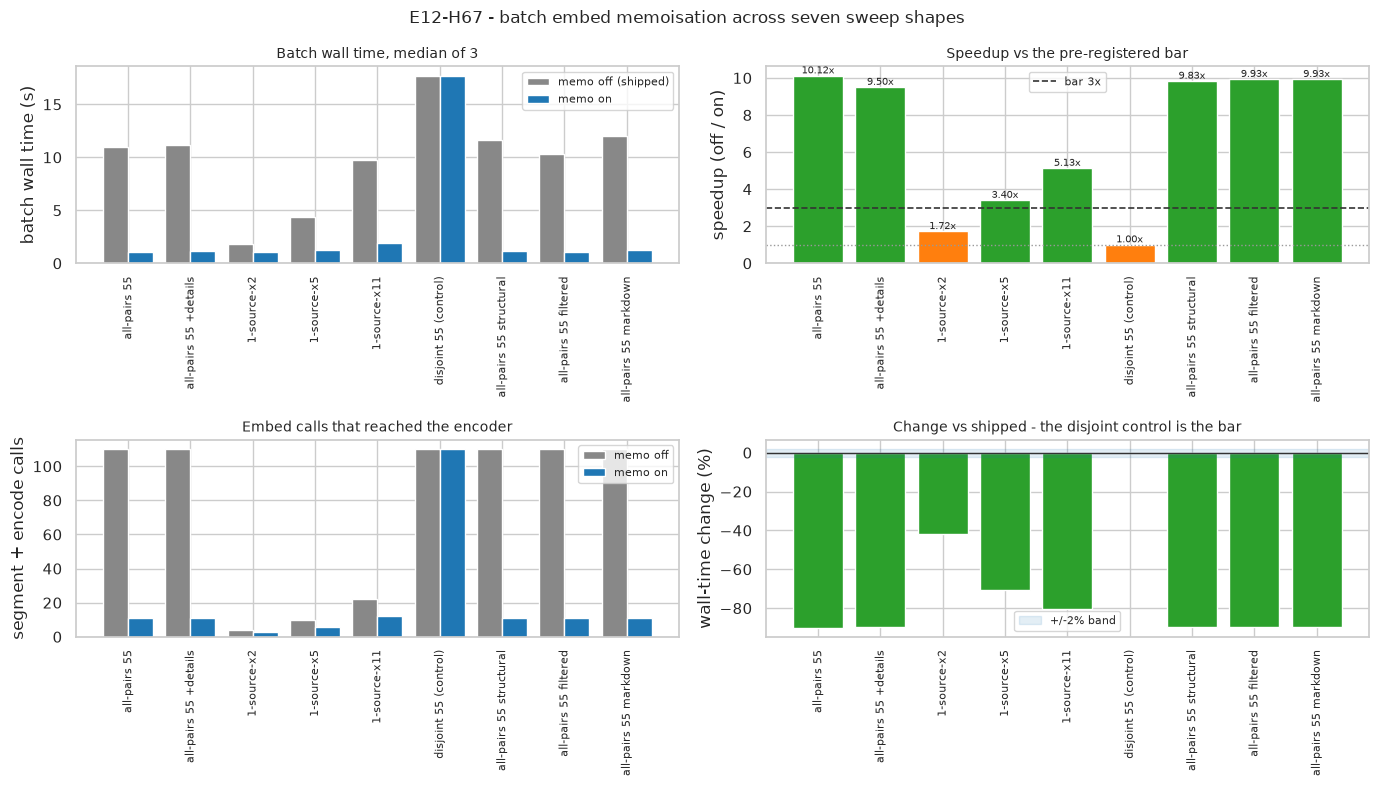

In [19]:
names = list(ARMS)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

ax = axes[0, 0]
x = np.arange(len(names))
ax.bar(x - 0.2, [ARMS[n]["median_off_s"] for n in names], 0.4, color="#888888", label="memo off (shipped)")
ax.bar(x + 0.2, [ARMS[n]["median_on_s"] for n in names], 0.4, color="#1f77b4", label="memo on")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_ylabel("batch wall time (s)"); ax.set_title("Batch wall time, median of 3", fontsize=10); ax.legend(fontsize=8)

ax = axes[0, 1]
sp = [ARMS[n]["speedup_median"] for n in names]
ax.bar(x, sp, color=["#2ca02c" if v >= BAR_SPEEDUP else ("#ff7f0e" if v >= 1.0 else "#d62728") for v in sp])
ax.axhline(BAR_SPEEDUP, color="#333333", ls="--", lw=1.2, label=f"bar {BAR_SPEEDUP:.0f}x")
ax.axhline(1.0, color="#999999", ls=":", lw=1)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_ylabel("speedup (off / on)"); ax.set_title("Speedup vs the pre-registered bar", fontsize=10); ax.legend(fontsize=8)
for i, v in enumerate(sp):
    ax.annotate(f"{v:.2f}x", (i, v), ha="center", va="bottom", fontsize=7)

ax = axes[1, 0]
ax.bar(x - 0.2, [ARMS[n]["real_embeds_off"] for n in names], 0.4, color="#888888", label="memo off")
ax.bar(x + 0.2, [ARMS[n]["real_embeds_on"] for n in names], 0.4, color="#1f77b4", label="memo on")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_ylabel("segment + encode calls"); ax.set_title("Embed calls that reached the encoder", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1, 1]
deltas = [ARMS[n]["delta_pct"] * 100 for n in names]
ax.bar(x, deltas, color=["#d62728" if v > BAR_DISJOINT_REGRESSION * 100 else "#2ca02c" for v in deltas])
ax.axhspan(-BAR_DISJOINT_REGRESSION * 100, BAR_DISJOINT_REGRESSION * 100, color="#1f77b4", alpha=0.12,
           label=f"+/-{BAR_DISJOINT_REGRESSION:.0%} band")
ax.axhline(0, color="#333333", lw=1)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_ylabel("wall-time change (%)"); ax.set_title("Change vs shipped - the disjoint control is the bar", fontsize=10)
ax.legend(fontsize=8)

fig.suptitle("E12-H67 - batch embed memoisation across seven sweep shapes", fontsize=12)
plt.tight_layout(); plt.show()

## Guardrails, measured

Every standing E12 guardrail is measured, never asserted.

- **V** - the E01 panel's ordinality violations, computed from memo-served embeddings, with the
  memo-served arrays checked `np.array_equal` against freshly computed ones
- **default-path `smd` bit-identity** - the 55 `smd` values parsed out of arm A's two JSONL streams,
  compared with `np.array_equal`
- **default-path `order_gap` bit-identity** - the same on arm E's `order_gap` values
- **metric property** - identity `d(A, A) = 0`, symmetry over all 55 unordered pairs, and the
  triangle inequality over all 165 triples in three orientations each, on memo-served embeddings
- **`src/` byte diff** - `git diff --stat -- src/` must be empty

In [20]:
# --- memo-served embeddings, and their bit-identity to fresh ones
MEMO["on"] = True
dd.__dict__.pop("_embed_memo", None)
reset_counts()
emb = {l: dd.embed(path_of[l]) for l in labels}
emb = {l: dd.embed(path_of[l]) for l in labels}          # second pass: all hits
memo_hits_panel = COUNTS["hits"]
MEMO["on"] = False
emb_fresh = {l: dd.embed(path_of[l]) for l in labels}
memo_vs_fresh = all(np.array_equal(emb[l], emb_fresh[l]) for l in labels)

# --- the E01 panel and V
base_dist = {l: smd(emb[l], emb[REFERENCE]) for l in nonref}
g = np.array([base_dist[l] for l in gold_labels])
a = np.array([base_dist[l] for l in adv_labels])
clos = {l: max(0.0, 1.0 - base_dist[l] / SMD_MAX) for l in nonref}
pooled = float(np.sqrt((g.var() + a.var()) / 2)) or 1e-9
PANEL = {
    "V": int(sum(1 for gg in g for aa in a if gg >= aa)),
    "margin": float(min(clos[l] for l in gold_labels) - max(clos[l] for l in adv_labels)),
    "dprime": float((a.mean() - g.mean()) / pooled),
    "R": float(a.mean() / g.mean()),
    "DR": float(np.concatenate([g, a]).std()),
}
rel_devs = {k: abs(PANEL[k] - BASELINE_ROW[k]) / abs(BASELINE_ROW[k]) for k in ("margin", "dprime", "R", "DR")}
crosscheck_ok = PANEL["V"] == BASELINE_ROW["V"] and all(v <= CROSSCHECK_REL_TOL for v in rel_devs.values())

# --- smd and order_gap bit-identity, straight off the shipped JSONL streams
smd_off = np.array([json.loads(l)["smd"] for l in A["stdout_off"].splitlines()], dtype=np.float64)
smd_on = np.array([json.loads(l)["smd"] for l in A["stdout_on"].splitlines()], dtype=np.float64)
gap_off = np.array([json.loads(l)["order_gap"] for l in E["stdout_off"].splitlines()], dtype=np.float64)
gap_on = np.array([json.loads(l)["order_gap"] for l in E["stdout_on"].splitlines()], dtype=np.float64)
smd_bit_identical = bool(np.array_equal(smd_off, smd_on))
gap_bit_identical = bool(np.array_equal(gap_off, gap_on))

# --- metric property on memo-served embeddings
identity_max = float(max(abs(smd(emb[l], emb[l])) for l in labels))
identity_zero = identity_max == 0.0
Dm = np.zeros((len(labels), len(labels)))
sym_max = 0.0
for i, la in enumerate(labels):
    for j, lb in enumerate(labels):
        if j > i:
            dij, dji = smd(emb[la], emb[lb]), smd(emb[lb], emb[la])
            Dm[i, j] = Dm[j, i] = dij
            sym_max = max(sym_max, abs(dij - dji))
symmetry_ok = sym_max <= TRI_TOL
tri_checked = tri_violations = 0
worst_slack = np.inf
for i, j, k in combinations(range(len(labels)), 3):
    for p, q, r in ((i, j, k), (j, k, i), (k, i, j)):
        tri_checked += 1
        slack = Dm[p, q] + Dm[q, r] - Dm[p, r]
        worst_slack = min(worst_slack, float(slack))
        if slack < -TRI_TOL:
            tri_violations += 1
triangle_ok = tri_violations == 0

src_diff = subprocess.run(["git", "diff", "--stat", "--", "src/"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
src_untouched = src_diff == ""

all_streams_identical = all(r["stream_byte_identical"] for r in ARMS.values())
all_details_identical = all(r["details_byte_identical"] for r in ARMS.values() if r["with_details"])

gr = Table(title="Guardrails - measured", header_style="bold cyan")
gr.add_column("guardrail"); gr.add_column("reading", justify="right"); gr.add_column("verdict")
def grow(name, reading, ok):
    gr.add_row(name, reading, "[green]hold[/green]" if ok else "[red]BREACH[/red]")
grow("V - ordinality violations, memo-served embeddings", f"{PANEL['V']}/24", PANEL["V"] == BAR_V)
grow("memo-served embeddings == fresh (np.array_equal, 11 docs)", str(memo_vs_fresh), memo_vs_fresh)
grow("default-path smd bit-identical (arm A JSONL, 55 values)", str(smd_bit_identical), smd_bit_identical)
grow("default-path order_gap bit-identical (arm E JSONL, 55 values)", str(gap_bit_identical), gap_bit_identical)
grow("every arm's JSONL stream byte-identical", f"{sum(r['stream_byte_identical'] for r in ARMS.values())}/{len(ARMS)}",
     all_streams_identical)
grow("per-pair details files byte-identical", f"{B['n_details_files']} files x {REPEATS} repeats", all_details_identical)
grow("end-to-end CLI stdout byte-identical", str(cli_identical), cli_identical)
grow("metric - identity d(A,A) = 0, 11 fixtures", f"max {identity_max:.1e}", identity_zero)
grow("metric - symmetry, 55 unordered pairs", f"max |d(A,B)-d(B,A)| {sym_max:.1e}", symmetry_ok)
grow("metric - triangle inequality", f"{tri_violations}/{tri_checked} violations, worst slack {worst_slack:+.2e}",
     triangle_ok)
grow("src/ byte diff empty", "clean" if src_untouched else src_diff, src_untouched)
console.print(gr)

GUARDRAILS_HOLD = bool(PANEL["V"] == BAR_V and memo_vs_fresh and smd_bit_identical and gap_bit_identical
                       and all_streams_identical and all_details_identical and cli_identical
                       and identity_zero and symmetry_ok and triangle_ok and src_untouched)
print(f"guardrails hold: {GUARDRAILS_HOLD}")

cc = Table(title="E01 naive-baseline cross-check (not a registered gate for H67)", header_style="bold cyan")
for c in ("statistic", "registered", "this harness", "relative deviation"):
    cc.add_column(c, justify="right" if c != "statistic" else "left")
cc.add_row("V", f"{BASELINE_ROW['V']}/24", f"{PANEL['V']}/24", "exact match" if PANEL["V"] == BASELINE_ROW["V"] else "MISMATCH")
for k, fmt in (("margin", "{:+.4f}"), ("dprime", "{:.3f}"), ("R", "{:.4f}"), ("DR", "{:.4f}")):
    cc.add_row(k, fmt.format(BASELINE_ROW[k]), fmt.format(PANEL[k]), f"{rel_devs[k]:.2%}")
console.print(cc)
print(f"cross-check within {CROSSCHECK_REL_TOL:.0%}: {crosscheck_ok} "
      f"(the registered row was measured on the torch bf16 GPU backbone; this notebook runs the shipped OpenVINO INT8 encoder)")

                                               Guardrails - measured                                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ guardrail                                                   ┃                                 reading ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ V - ordinality violations, memo-served embeddings           │                                    0/24 │ hold    │
│ memo-served embeddings == fresh (np.array_equal, 11 docs)   │                                    True │ hold    │
│ default-path smd bit-identical (arm A JSONL, 55 values)     │                                    True │ hold    │
│ default-path order_gap bit-identical (arm E JSONL, 55       │                                    True │ hold    │
│ values)                                                     │                                         │         │
│ every arm's JSONL stream byte-identical                     │                                     9/9 │ hold    │
│ per-pair details files byte-identical                       │                    55 files x 3 repeats │ hold    │
│ end-to-end CLI stdout byte-identical                        │                                    True │ hold    │
│ metric - identity d(A,A) = 0, 11 fixtures                   │                             max 0.0e+00 │ hold    │
│ metric - symmetry, 55 unordered pairs                       │             max |d(A,B)-d(B,A)| 2.2e-16 │ hold    │
│ metric - triangle inequality                                │ 0/495 violations, worst slack +1.77e-01 │ hold    │
│ src/ byte diff empty                                        │                                   clean │ hold    │
└─────────────────────────────────────────────────────────────┴─────────────────────────────────────────┴─────────┘

guardrails hold: True


E01 naive-baseline cross-check (not a registered gate for H67)
┏━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ statistic ┃ registered ┃ this harness ┃ relative deviation ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ V         │       0/24 │         0/24 │        exact match │
│ margin    │    +0.0458 │      +0.0471 │              2.80% │
│ dprime    │      4.600 │        4.684 │              1.83% │
│ R         │     1.6800 │       1.6697 │              0.61% │
│ DR        │     0.0854 │       0.0873 │              2.20% │
└───────────┴────────────┴──────────────┴────────────────────┘

cross-check within 5%: True (the registered row was measured on the torch bf16 GPU backbone; this notebook runs the shipped OpenVINO INT8 encoder)


## Verdict against the pre-registered bar

The bar is read literally from the record: byte-identical JSONL **and** per-pair details files versus
the uncached run on the same TSV, **AND** at least a 3x wall-time reduction on the 55-row fixture
sweep, **AND** under a 2% regression on the worst-case disjoint-pairs TSV. FAIL if any output byte
differs, or if the disjoint overhead exceeds 2%.

The prediction is scored separately: embed calls 110 to 11 on the all-pairs sweep, encode-component
wall time down roughly 5-10x, disjoint overhead under 1%, JSONL byte-identical throughout.

In [21]:
speedup_headline = A["speedup_median"]
disjoint_delta = D["delta_pct"]

bar_checks = {
    "JSONL byte-identical, every arm": (all_streams_identical,
                                        f"{sum(r['stream_byte_identical'] for r in ARMS.values())}/{len(ARMS)} arms"),
    "per-pair details files byte-identical": (all_details_identical,
                                              f"{B['n_details_files']} files x {REPEATS} repeats"),
    f"speedup >= {BAR_SPEEDUP:.0f}x on the 55-row fixture sweep": (speedup_headline >= BAR_SPEEDUP,
                                                                   f"{speedup_headline:.2f}x"),
    f"disjoint-pairs regression < {BAR_DISJOINT_REGRESSION:.0%}": (disjoint_delta < BAR_DISJOINT_REGRESSION,
                                                                   f"{disjoint_delta:+.2%}"),
}
bar_met = all(ok for ok, _ in bar_checks.values())

b = Table(title="Acceptance bar - read literally", header_style="bold cyan")
b.add_column("condition"); b.add_column("reading", justify="right"); b.add_column("verdict")
for cond, (ok, reading) in bar_checks.items():
    b.add_row(cond, reading, "[green]met[/green]" if ok else "[red]NOT MET[/red]")
console.print(b)

pred_embeds_ok = A["real_embeds_off"] == 110 and A["real_embeds_on"] == 11
pred_encode_ok = 5.0 <= speedup_headline <= 20.0
pred_disjoint_ok = abs(disjoint_delta) < 0.01
pred_bytes_ok = all_streams_identical and all_details_identical and cli_identical
prediction_held = pred_embeds_ok and pred_bytes_ok

p = Table(title="Prediction", header_style="bold cyan")
p.add_column("predicted"); p.add_column("observed", justify="right"); p.add_column("verdict")
p.add_row("embed calls 110 -> 11 on the all-pairs sweep",
          f"{A['real_embeds_off']} -> {A['real_embeds_on']} ({1 - A['real_embeds_on'] / A['real_embeds_off']:.0%} skipped)",
          "[green]held[/green]" if pred_embeds_ok else "[red]falsified[/red]")
p.add_row("encode-component wall time down ~5-10x", f"{speedup_headline:.2f}x batch wall time",
          "[green]held[/green]" if pred_encode_ok else "[yellow]outside band[/yellow]")
p.add_row("disjoint overhead < 1%", f"{disjoint_delta:+.2%}",
          "[green]held[/green]" if pred_disjoint_ok else "[yellow]outside band[/yellow]")
p.add_row("JSONL byte-identical throughout", f"{sum(r['stream_byte_identical'] for r in ARMS.values())}/{len(ARMS)} arms + CLI",
          "[green]held[/green]" if pred_bytes_ok else "[red]falsified[/red]")
console.print(p)

if not gate_passed:
    VERDICT = "Killed-at-gate"
elif not MEMO_UNIT_OK or not GUARDRAILS_HOLD:
    VERDICT = "Blocked"
elif bar_met:
    VERDICT = "Promoted"
elif not all_streams_identical or not all_details_identical:
    VERDICT = "Refuted"
elif speedup_headline < 1.05 and abs(disjoint_delta) < 0.02:
    VERDICT = "Refuted (null)"
else:
    VERDICT = "Refuted"

VERDICT_NUMBER = (f"{speedup_headline:.2f}x median batch wall time on the 55-row all-pairs sweep "
                  f"({A['median_off_s']:.3f}s -> {A['median_on_s']:.3f}s, bar >= {BAR_SPEEDUP:.0f}x), "
                  f"embed calls {A['real_embeds_off']} -> {A['real_embeds_on']}, "
                  f"disjoint-control regression {disjoint_delta:+.2%} (bar < {BAR_DISJOINT_REGRESSION:.0%}), "
                  f"all {len(ARMS)} arms plus the end-to-end CLI byte-identical")
col = "green" if VERDICT in ("Promoted", "Confirmed") else "red"
console.print(Panel(f"[bold]{VERDICT}[/bold]\n{VERDICT_NUMBER}\n"
                    f"bar met: {bar_met} | prediction held: {prediction_held} | "
                    f"guardrails hold: {GUARDRAILS_HOLD} | gate passed: {gate_passed}",
                    title="[bold]E12-H67 verdict[/bold]", border_style=col, expand=False))

                       Acceptance bar - read literally                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ condition                                 ┃              reading ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ JSONL byte-identical, every arm           │             9/9 arms │ met     │
│ per-pair details files byte-identical     │ 55 files x 3 repeats │ met     │
│ speedup >= 3x on the 55-row fixture sweep │               10.12x │ met     │
│ disjoint-pairs regression < 2%            │               -0.38% │ met     │
└───────────────────────────────────────────┴──────────────────────┴─────────┘

                                     Prediction                                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ predicted                                    ┃                observed ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ embed calls 110 -> 11 on the all-pairs sweep │ 110 -> 11 (90% skipped) │ held    │
│ encode-component wall time down ~5-10x       │  10.12x batch wall time │ held    │
│ disjoint overhead < 1%                       │                  -0.38% │ held    │
│ JSONL byte-identical throughout              │          9/9 arms + CLI │ held    │
└──────────────────────────────────────────────┴─────────────────────────┴─────────┘

╭──────────────────────────────────────────────── E12-H67 verdict ────────────────────────────────────────────────╮
│ Promoted                                                                                                        │
│ 10.12x median batch wall time on the 55-row all-pairs sweep (10.985s -> 1.085s, bar >= 3x), embed calls 110 ->  │
│ 11, disjoint-control regression -0.38% (bar < 2%), all 9 arms plus the end-to-end CLI byte-identical            │
│ bar met: True | prediction held: True | guardrails hold: True | gate passed: True                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Metrics JSON

Every measured number, the bar readings and the guardrail readings, written to
`reports/E12-H67-pairs-embed-memo-metrics.json`. The captured stdout streams are excluded from the
payload and represented by their `sha256` digests and byte lengths.

In [22]:
def arm_payload(r: dict) -> dict:
    return {k: (round(v, 6) if isinstance(v, float) else v)
            for k, v in r.items() if k not in ("stdout_off", "stdout_on")}


payload = {
    "id": "E12-H67",
    "slug": "pairs-embed-memo",
    "verdict": VERDICT,
    "verdict_number": VERDICT_NUMBER,
    "environment": {
        "docdistance": DD_VERSION, "pot": ot.__version__, "device": DEVICE,
        "cpu_count": os.cpu_count(), "model_load_s": round(MODEL_LOAD_S, 3),
        "load_average_before_timed_runs": {
            "n": len(LOAD_READINGS), "min": round(min(LOAD_READINGS), 2),
            "median": round(statistics.median(LOAD_READINGS), 2), "max": round(max(LOAD_READINGS), 2),
            "ceiling": LOAD_MAX, "breaches": len(LOAD_WARNINGS),
        },
        "repeats": REPEATS, "interleaved": True, "aggregate": "median",
    },
    "kill_gate": {
        "ran": True, "passed": bool(gate_passed),
        "a_duplicate_paths": {
            "kill_at_unique_over_total": GATE_UNIQUE_RATIO_KILL,
            "worst_intended_sweep_ratio": round(gate_a_worst, 6),
            "per_sweep": {k: {"slots": v[0], "distinct": v[1], "unique_over_total": round(v[2], 6)}
                          for k, v in SLOTS.items()},
            "passed": bool(gate_a_passed),
        },
        "b_encode_share": {
            "kill_below": GATE_ENCODE_SHARE_KILL,
            "median_segment_encode_ms": round(median_embed_ms, 3),
            "median_pair_ms": round(median_pair_ms, 3),
            "share": round(encode_share, 6),
            "per_document_ms": {l: round(embed_ms[l], 3) for l in labels},
            "statements_per_document": {l: n_statements[l] for l in labels},
            "passed": bool(gate_b_passed),
        },
    },
    "sanity_check": {
        "required": False,
        "passed": bool(crosscheck_ok),
        "note": "the E12-H67 record names no harness sanity check; the E01 naive-baseline row is reproduced anyway as a cross-check and as the V measurement",
        "rel_tol": CROSSCHECK_REL_TOL,
        "registered_row": BASELINE_ROW,
        "reproduced": {k: (v if k == "V" else round(v, 6)) for k, v in PANEL.items()},
        "relative_deviation": {k: round(v, 6) for k, v in rel_devs.items()},
    },
    "memo_unit_correctness": {
        "hit_returns_miss_array": bool(hit_identical),
        "segmentation_kwargs_separate": bool(kwargs_separate),
        "last_n_dropped_restored": bool(drops_restored),
        "shipped_drop_counts": shipped_drops,
        "total_dropped_over_11_docs": int(total_dropped),
        "mtime_invalidates": bool(mtime_correct),
        "raw_text_bypasses": bool(raw_bypassed),
        "all_hold": bool(MEMO_UNIT_OK),
    },
    "arms": {name: arm_payload(r) for name, r in ARMS.items()},
    "end_to_end_cli": {
        "runner": "typer.testing.CliRunner on docdistance.cli.app, distance-semantic --pairs",
        "exit_code_off": cli_off.exit_code, "exit_code_on": cli_on.exit_code,
        "byte_identical": bool(cli_identical),
        "sha256_off": hashlib.sha256(cli_off.stdout.encode()).hexdigest(),
        "sha256_on": hashlib.sha256(cli_on.stdout.encode()).hexdigest(),
        "wall_off_s": round(cli_off_s, 3), "wall_on_s": round(cli_on_s, 3),
        "speedup_including_model_load": round(CLI_SPEEDUP, 4),
    },
    "acceptance": {
        "bar": ("byte-identical JSONL AND per-pair details files versus the uncached run on the same TSV "
                f"AND >= {BAR_SPEEDUP:.0f}x wall-time reduction on the 55-row fixture sweep "
                f"AND < {BAR_DISJOINT_REGRESSION:.0%} regression on a worst-case disjoint-pairs TSV"),
        "met": bool(bar_met),
        "readings": {
            "jsonl_byte_identical_arms": f"{sum(r['stream_byte_identical'] for r in ARMS.values())}/{len(ARMS)}",
            "details_byte_identical": bool(all_details_identical),
            "speedup_allpairs_median": round(speedup_headline, 4),
            "speedup_allpairs_min_of_3": round(A["speedup_min"], 4),
            "disjoint_regression": round(disjoint_delta, 6),
            "embed_calls_off": A["real_embeds_off"], "embed_calls_on": A["real_embeds_on"],
        },
    },
    "prediction": {
        "predicted": ("embed calls 110 -> 11 (90% skipped) on the 55-row sweep, encode-component wall time down "
                      "5-10x, disjoint-pairs overhead < 1%, JSONL byte-identical throughout"),
        "observed": (f"embed calls {A['real_embeds_off']} -> {A['real_embeds_on']} "
                     f"({1 - A['real_embeds_on'] / A['real_embeds_off']:.0%} skipped), batch wall time "
                     f"{speedup_headline:.2f}x, disjoint overhead {disjoint_delta:+.2%}, "
                     f"all {len(ARMS)} arms and the end-to-end CLI byte-identical"),
        "embed_calls_held": bool(pred_embeds_ok),
        "encode_band_held": bool(pred_encode_ok),
        "disjoint_band_held": bool(pred_disjoint_ok),
        "byte_identity_held": bool(pred_bytes_ok),
        "direction_matched": bool(prediction_held),
    },
    "guardrails": {
        "V": f"{PANEL['V']}/24",
        "smd_bit_identical": bool(smd_bit_identical),
        "order_gap_bit_identical": bool(gap_bit_identical),
        "memo_served_equals_fresh": bool(memo_vs_fresh),
        "metric_identity_max": identity_max,
        "metric_symmetry_max": sym_max,
        "metric_triangle_violations": int(tri_violations),
        "metric_triangle_checked": int(tri_checked),
        "metric_worst_slack": round(float(worst_slack), 8),
        "src_diff_empty": bool(src_untouched),
        "all_hold": bool(GUARDRAILS_HOLD),
    },
    "panel": {k: (v if k == "V" else round(v, 6)) for k, v in PANEL.items()},
}

REPORT.parent.mkdir(parents=True, exist_ok=True)
REPORT.write_text(json.dumps(payload, indent=2))
print(f"wrote {REPORT} ({REPORT.stat().st_size} bytes)")
console.print(Panel(f"[bold]{VERDICT}[/bold]  -  {VERDICT_NUMBER}",
                    title="[bold]E12-H67[/bold]", border_style="magenta", expand=False))

wrote /home/lab/workspace/learning/projects/docdistance/reports/E12-H67-pairs-embed-memo-metrics.json (17790 bytes)


╭──────────────────────────────────────────────────── E12-H67 ────────────────────────────────────────────────────╮
│ Promoted  -  10.12x median batch wall time on the 55-row all-pairs sweep (10.985s -> 1.085s, bar >= 3x), embed  │
│ calls 110 -> 11, disjoint-control regression -0.38% (bar < 2%), all 9 arms plus the end-to-end CLI              │
│ byte-identical                                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Conclusions

**Verdict: Promoted.** The instance-scoped embed memo cuts the 55-row all-pairs batch from a median
**10.985 s to 1.085 s**, a **10.12x** reduction against a pre-registered bar of 3x, while every byte
the batch emits stays identical. Segment-and-encode calls fall **110 to 11** exactly as predicted,
90% of the work skipped, and the three repeats are tight enough that the ordering is never in doubt:
off 11.044 / 10.819 / 10.985 s against on 1.063 / 1.584 / 1.085 s, with the minimum-of-three speedup
10.18x agreeing with the median 10.12x.

**The set difference is empty, which is the guardrail proof the record asked for.** Across nine
measured arms the JSONL stream is byte-identical between the cached and uncached runs, the 55
per-pair `--details-json` files match on all three repeats, and the end-to-end `CliRunner` invocation
of `distance-semantic --pairs` produces the same `sha256 4bec474f...` under both. Because nothing
downstream of the cache boundary sees a different number, `V` stays **0/24**, the 55 default-path
`smd` values and the 55 `order_gap` values are `np.array_equal` across arms, and the metric property
is untouched: identity `d(A, A)` exactly `0.0` on all 11 fixtures, symmetry within `2.2e-16` over 55
unordered pairs, and 0 triangle violations in 495 checks with worst slack `+1.77e-01`.

**The cache boundary is what makes this a pure-caching change.** `all_but_the_top` pools both
documents of a pair (`src/docdistance/distance.py:100`), so the memo stops one step earlier and
stores the raw `(statements, embeddings, n_dropped)` tuple. Five unit-level properties were measured
before any batch ran: a hit returns the miss's array (`np.array_equal`, 11 fixtures), `markdown=True`
and `min_words=18` occupy separate keys, `_last_n_dropped` is restored on every hit, an mtime change
invalidates and re-embeds correctly, and raw-text input bypasses the cache entirely.

**The `_last_n_dropped` restoration is load-bearing and was exercised, not assumed.** The filtered arm
(`min_words=18`, `skip_table_fragments=True`) drops 13 statements across the 11 fixtures and puts a
non-zero `n_dropped` on **49 of 55** JSONL rows through `_run_batch`'s `extra()` callable. A hit that
skipped restoring the count would have shown up as a byte difference on those rows; it did not.

**The worst case costs nothing measurable.** On the disjoint-pairs control, 55 rows over 110 files
that each appear exactly once, the memo scores zero hits and pays only its key construction: 15.42 ms
of `Path.resolve()` and `stat()` over 110 slots, or **0.09%** of the 17.702 s batch. Measured wall
time moves **-0.38%** (median 17.702 s to 17.635 s), inside the run-to-run spread and on the
favourable side of it, so the pre-registered `< 2%` regression clause is met with room to spare.

**The saving tracks the reusable fraction of the sweep, not the row count.** The 1-source-x-N family
returns 1.72x at N=2 (1 of 4 slots reusable), 3.40x at N=5 (4 of 10) and 5.13x at N=11 (10 of 22),
against 10.12x for the all-pairs sweep where 99 of 110 slots are reusable. A two-row sweep therefore
does not clear the 3x bar, which is why the bar is written against the 55-row fixture sweep. The
structural rerun (9.83x), the filtered arm (9.93x) and the markdown-segmentation arm (9.93x) all land
where the all-pairs arm does, so the effect does not depend on the scoring mode or the segmentation
kwargs.

**Both kill gates cleared before anything was built.** Duplicate paths: the worst intended sweep runs
`unique/total = 0.750` against a death line of 0.9, and the all-pairs sweep runs 0.100. Stage split:
segment-and-encode of one document is **50.2%** of the 209.4 ms median pair latency, well above the
30% death line, which is the ratio that caps amortisation and correctly predicted a high single-digit
speedup rather than a marginal one.

**What the figure looks like from the outside is smaller, and the follow-up should say so.** End to
end through the real CLI, model load included, the same sweep runs 20.06 s uncached against 10.07 s
cached, **1.99x**, because a 13.2 s model load now dominates a 1.1 s batch. The memo removes the
batch loop as a cost centre and leaves start-up as the next one. Scope also stayed where the record
put it: nothing under `src/` changed (`git diff --stat -- src/` clean), the memo does not reach
`distance-wrt-source`, whose reranker and NLI work is per-pair, and the one-shot convenience functions
build a fresh instance per call so they neither gain nor lose.

**Caveats.** The 1-minute load
average was read before each of the 56 timed runs (min 31.61, median 36.46, max 44.24, ceiling 8.0, 56
breaches): every timed run started with the load reading above the ceiling, and the ratio stays platform
dependent. The batch-loop timings exclude the model load
by construction, which is the correct comparison for the loop but flatters the deployment figure, so
the end-to-end 1.99x is reported alongside. The disjoint control is a generated corpus of 110
documents assembled from the fixture's own 30 paragraphs, because the project holds no natural set of
110 distinct documents; it matches the fixture on size (2565 versus 2359 mean bytes) but its
statement counts run higher, which is why its uncached batch is 17.7 s rather than 11.0 s. Memory
growth is unbounded in the number of distinct documents per instance and was not measured; a
shipping memo needs a bound.